# cuDF-Polars filter analysis

This notebook measures only the native filter operation for CPU, CUDA, and Triton. Inputs, masks, backend conversions, and result validation are prepared outside the timed call.

In [15]:
from pathlib import Path
import sys

import numpy as np
import polars as pl
import pylibcudf as plc
from rmm.pylibrmm.stream import DEFAULT_STREAM

repo_root = Path.cwd().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd()
python_root = repo_root / 'python' / 'cudf_polars'
if str(python_root) not in sys.path:
    sys.path.insert(0, str(python_root))

from cudf_polars.analysis.operation_benchmark import time_cpu, time_cuda
from cudf_polars.containers import Column, DataFrame, DataType
from cudf_polars.triton.triton_conversion import (
    column_cudf_to_triton,
    dataframe_cudf_to_triton,
)

## Prepare equivalent inputs

The mask is materialized once per backend. The timed functions receive native objects and perform no conversion.

In [44]:
sizes = (200_000, 2_000_000, 20_000_000)
num_columns = 4
selectivity = 0.5
warmups = 3
repeats = 10
cudf_stream = DEFAULT_STREAM

filter_cases = {}

for num_rows in sizes:
    num_columns = 8
    rng = np.random.default_rng(42)

    values = {
        f'c{i}': rng.standard_normal(num_rows).astype(np.float32)
        for i in range(num_columns)
    }

    mask_values = rng.random(num_rows) < 0.5

    cpu_frame = pl.DataFrame(values)
    cpu_mask = pl.Series('mask', mask_values)

    cudf_stream = DEFAULT_STREAM
    cudf_frame = DataFrame.from_polars(cpu_frame, stream=cudf_stream)

    cudf_mask = Column(
        plc.Column.from_arrow(cpu_mask, stream=cudf_stream),
        dtype=DataType(pl.Boolean()),
        name='mask',
    )

    triton_frame = dataframe_cudf_to_triton(cudf_frame)
    triton_mask = column_cudf_to_triton(
        cudf_mask,
        name='mask',
        stream=cudf_stream,
    )

    cpu_operation = lambda frame=cpu_frame, mask=cpu_mask: frame.filter(mask)
    cuda_operation = lambda frame=cudf_frame, mask=cudf_mask: frame.filter(mask)
    triton_operation = lambda frame=triton_frame, mask=triton_mask: frame.filter(mask)

    expected_rows = mask_values.sum()

    print(
        f'{num_rows:,} rows, '
        f'{num_columns} columns, '
        f'selectivity={mask_values.mean():.3f}'
    )
    print(expected_rows)

    filter_cases[num_rows] = {
        "cpu": cpu_operation,
        "cuda": cuda_operation,
        "triton": triton_operation,
        "expected_rows": expected_rows,
    }

200,000 rows, 8 columns, selectivity=0.501
100247
2,000,000 rows, 8 columns, selectivity=0.499
998734
20,000,000 rows, 8 columns, selectivity=0.500
10001179


## Benchmark

CPU timing uses `perf_counter_ns`. CUDA and Triton timing use CUDA events recorded on the same RMM-backed stream. Warmups and synchronization are outside the measured operation interval.

In [48]:
benchmark_rows = []
for num_rows, case in filter_cases.items():
    timings = {
        "cpu": time_cpu(case["cpu"], warmups=warmups, repeats=repeats),
        "cuda": time_cuda(
            case["cuda"],
            stream=cudf_stream,
            warmups=warmups,
            repeats=repeats,
        ),
        "triton": time_cuda(
            case["triton"],
            stream=cudf_stream,
            warmups=warmups,
            repeats=repeats,
        ),
    }
    for backend, timing in timings.items():
        benchmark_rows.append(
            {
                "operation": "filter",
                "backend": backend,
                "rows": num_rows,
                "mean_ms": timing.mean_ms,
                "median_ms": timing.median_ms,
                "min_ms": timing.min_ms,
            }
        )
    print(f"completed filter case: {num_rows:,} rows")

filter_results = pl.DataFrame(benchmark_rows)
filter_results

completed filter case: 200,000 rows
completed filter case: 2,000,000 rows
completed filter case: 20,000,000 rows


operation,backend,rows,mean_ms,median_ms,min_ms
str,str,i64,f64,f64,f64
"""filter""","""cpu""",200000,0.8498595,0.554404,0.316701
"""filter""","""cuda""",200000,1.96823,1.343488,0.93184
"""filter""","""triton""",200000,1.375437,1.122816,1.007616
"""filter""","""cpu""",2000000,4.464543,2.8127895,2.423946
"""filter""","""cuda""",2000000,14.75625,14.227968,11.561984
"""filter""","""triton""",2000000,0.818723,0.827392,0.770048
"""filter""","""cpu""",20000000,27.384657,27.244074,27.007071
"""filter""","""cuda""",20000000,15.07256,13.689184,12.422144
"""filter""","""triton""",20000000,7.673661,7.461888,6.499328


## Validate outside timing

Materializing or inspecting results is intentionally excluded from the benchmark. This check confirms that each implementation selected the same number of rows.

In [47]:
for num_rows, case in filter_cases.items():
    cpu_result = case["cpu"]()
    cuda_result = case["cuda"]()
    triton_result = case["triton"]()
    cudf_stream.synchronize()
    triton_result.stream.synchronize()

    expected_rows = case["expected_rows"]
    assert cpu_result.height == expected_rows
    assert cuda_result.num_rows == expected_rows
    assert triton_result.num_rows == expected_rows
    print(f"validated filter output: {num_rows:,} rows -> {expected_rows:,} rows")

validated filter output: 200,000 rows -> 100,247 rows
validated filter output: 2,000,000 rows -> 998,734 rows
validated filter output: 20,000,000 rows -> 10,001,179 rows


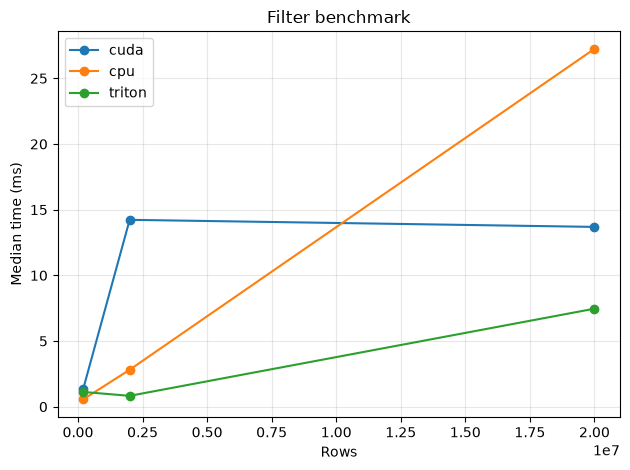

In [49]:
import matplotlib.pyplot as plt

plot_df = filter_results.sort("rows")

for backend in plot_df["backend"].unique():
    data = plot_df.filter(pl.col("backend") == backend)

    plt.plot(
        data["rows"].to_list(),
        data["median_ms"].to_list(),
        marker="o",
        label=backend,
    )

plt.xlabel("Rows")
plt.ylabel("Median time (ms)")
plt.title("Filter benchmark")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Join benchmark

The join benchmark prepares the key columns before timing. CPU uses Polars `join`, CUDA uses libcudf `inner_join`, and Triton uses the prepared `join_pairs` operation. No conversion, expression evaluation, or result inspection is included in the timed call.